In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

Load Data

In [ ]:
df = pd.read_excel("Employee-Attrition.xlsx")       

In [3]:
print(df.shape)         
print(df.dtypes)        
print(df.isnull().sum().sum())

(1470, 35)
Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel             int64
TotalWork

In [4]:
print(df['Attrition'].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


Data Visualization

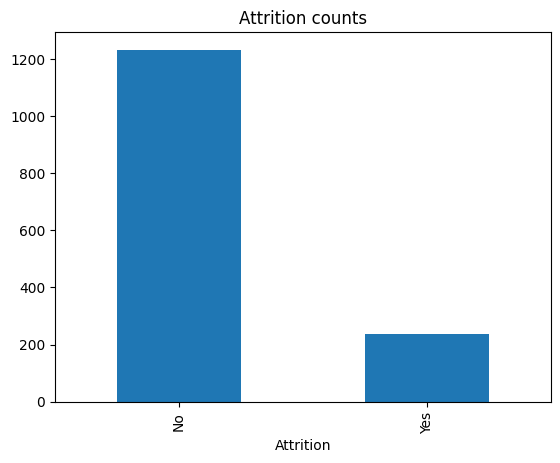

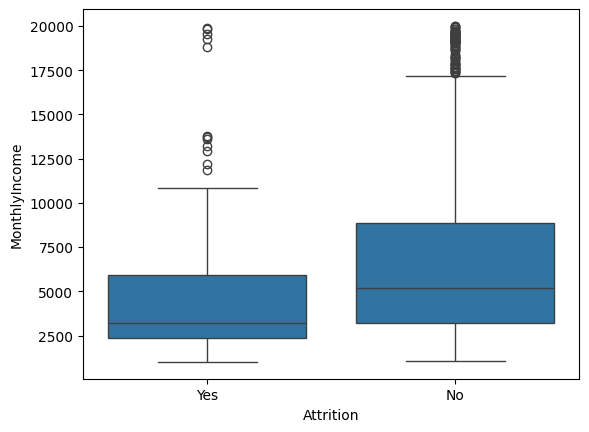

In [5]:
df['Attrition'].value_counts().plot(kind='bar', title='Attrition counts')
plt.show()

df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean())

sns.boxplot(data=df, x='Attrition', y='MonthlyIncome')
plt.show()

Data Cleaning

In [6]:
df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])

df['Attrition'] = df['Attrition'].map({'No': 0, 'Yes': 1})
df['PerformanceRating'] = df['PerformanceRating'].map({3: 0, 4: 1})

In [7]:
df['Age'].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

Feature engineering

In [8]:
df['TenureRatio'] = df['YearsInCurrentRole'] / df['YearsAtCompany'].replace(0, 1)

df['IncomePerYearWorked'] = df['MonthlyIncome'] / (df['TotalWorkingYears'] + 1)

satisfaction_cols = ['JobSatisfaction', 'EnvironmentSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance']
df['OverallSatisfaction'] = df[satisfaction_cols].mean(axis=1)

df['TenureCategory'] = pd.cut(
    df['YearsAtCompany'],
    bins=[-1, 2, 5, 10, 100],
    labels=['New (0-2y)', 'Early (3-5y)', 'Established (6-10y)', 'Veteran (10y+)']
)

perf_cols = ['PercentSalaryHike', 'TrainingTimesLastYear']
df['PerformanceScore'] = MinMaxScaler().fit_transform(df[perf_cols]).mean(axis=1)

engagement_cols = ['JobInvolvement', 'StockOptionLevel']
df['EngagementScore'] = MinMaxScaler().fit_transform(df[engagement_cols]).mean(axis=1)

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 60],
    labels=['18-25', '26-35', '36-45', '46-60']
)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TenureRatio,IncomePerYearWorked,OverallSatisfaction,TenureCategory,PerformanceScore,EngagementScore,AgeGroup
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,4,0,5,0.666667,665.888889,2.00,Established (6-10y),0.000000,0.333333,36-45
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,7,1,7,0.700000,466.363636,3.00,Established (6-10y),0.678571,0.333333,46-60
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,0,0,0.000000,261.250000,3.00,New (0-2y),0.392857,0.166667,36-45
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,7,3,0,0.875000,323.222222,3.25,Established (6-10y),0.250000,0.333333,26-35
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,2,2,2,1.000000,495.428571,2.50,New (0-2y),0.285714,0.500000,26-35


In [9]:
X = df.drop(columns=['Attrition', 'PerformanceRating'])
y_attrition = df['Attrition']

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

print(cat_cols)
print(len(num_cols), "numeric columns")

['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'TenureCategory', 'AgeGroup']
27 numeric columns


In [10]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TenureRatio,IncomePerYearWorked,OverallSatisfaction,TenureCategory,PerformanceScore,EngagementScore,AgeGroup
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,4,0,5,0.666667,665.888889,2.00,Established (6-10y),0.000000,0.333333,36-45
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,7,1,7,0.700000,466.363636,3.00,Established (6-10y),0.678571,0.333333,46-60
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,0,0,0.000000,261.250000,3.00,New (0-2y),0.392857,0.166667,36-45
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,7,3,0,0.875000,323.222222,3.25,Established (6-10y),0.250000,0.333333,26-35
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,2,2,2,1.000000,495.428571,2.50,New (0-2y),0.285714,0.500000,26-35


Train/Test

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_attrition, test_size=0.2, random_state=42, stratify=y_attrition
)

X_train.shape, X_test.shape

((1176, 36), (294, 36))

Preprocessing pipeline

In [12]:
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)  
X_test_processed = preprocessor.transform(X_test)  

X_train_processed.shape, X_test_processed.shape

((1176, 63), (294, 63))

Model Building

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [50]:
log_reg_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

tree_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

forest_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
])
knn_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])

log_reg_pipe.fit(X_train, y_train)
tree_pipe.fit(X_train, y_train)
forest_pipe.fit(X_train, y_train)
knn_pipe.fit(X_train, y_train)

print("All models trained.")

All models trained.


Evaluation

In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

In [46]:
pipelines = {
    'Logistic Regression': log_reg_pipe,
    'Decision Tree': tree_pipe,
    'Random Forest': forest_pipe,
    'K-Nearest Neighbors': knn_pipe
}

results = []
for name, pipe in pipelines.items():
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1] 
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'AUC': roc_auc_score(y_test, probs)
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.776,0.391,0.723,0.507,0.817
1,Decision Tree,0.786,0.333,0.340,0.337,0.605
2,Random Forest,0.847,0.667,0.085,0.151,0.757
3,K-Nearest Neighbors,0.840,0.500,0.085,0.145,0.579


Confusion MAtrix

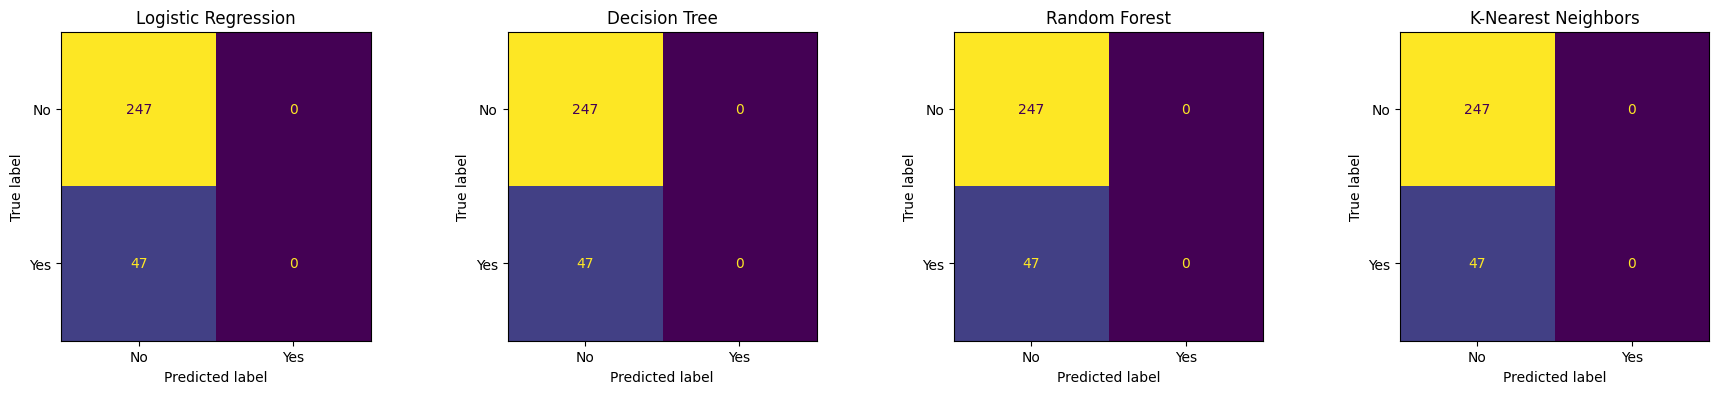

In [53]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

ROC curves

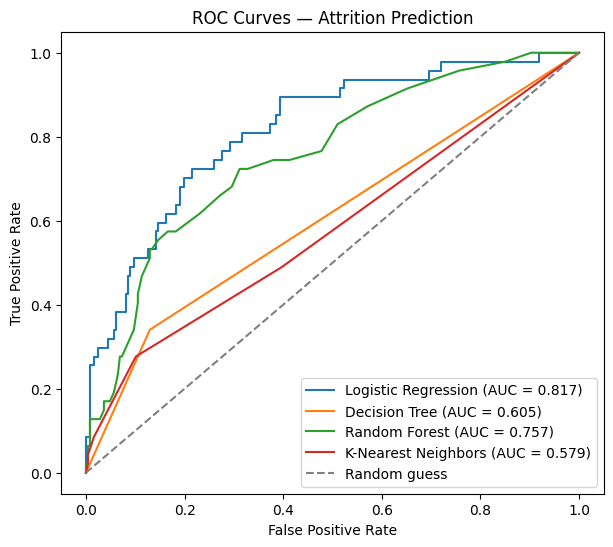

In [48]:
plt.figure(figsize=(7, 6))
for name, pipe in pipelines.items():
    probs = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Attrition Prediction')
plt.legend()
plt.show()

In [20]:
import joblib

joblib.dump(log_reg_pipe, "attrition_model.pkl")

print("Model saved as attrition_model.pkl")

Model saved as attrition_model.pkl


Perfomance Prediction

In [28]:
X_perf = df.drop(columns=['Attrition', 'PerformanceRating', 'PerformanceScore', 'PercentSalaryHike'])
y_performance = df['PerformanceRating']

cat_cols_perf = X_perf.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols_perf = X_perf.select_dtypes(exclude=['object', 'category']).columns.tolist()

New train/test split

In [29]:
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_perf, y_performance, test_size=0.2, random_state=42, stratify=y_performance
)

New preprocessing pipeline

In [30]:
preprocessor_perf = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_perf),
    ('num', StandardScaler(), num_cols_perf)
])

Model build

In [ ]:
log_reg_pipe_perf = Pipeline([('prep', preprocessor_perf),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])
tree_pipe_perf = Pipeline([('prep', preprocessor_perf),
    ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42))])
forest_pipe_perf = Pipeline([('prep', preprocessor_perf),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))])
knn_pipe_perf = Pipeline([('prep', preprocessor_perf),
    ('clf', KNeighborsClassifier(n_neighbors=5))])

log_reg_pipe_perf.fit(X_train_p, y_train_p)
tree_pipe_perf.fit(X_train_p, y_train_p)
forest_pipe_perf.fit(X_train_p, y_train_p)
knn_pipe_perf.fit(X_train_p, y_train_p)

print("All models trained.")

All models trained.


Evaluation

In [ ]:
pipelines_perf = {
    'Logistic Regression': log_reg_pipe_perf,
    'Decision Tree': tree_pipe_perf,
    'Random Forest': forest_pipe_perf,
    'K-Nearest Neighbors': knn_pipe_perf,
}

results_perf = []
for name, pipe in pipelines_perf.items():
    preds = pipe.predict(X_test_p)
    probs = pipe.predict_proba(X_test_p)[:, 1]
    results_perf.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_p, preds),
        'Precision': precision_score(y_test_p, preds, zero_division=0),
        'Recall': recall_score(y_test_p, preds),
        'F1': f1_score(y_test_p, preds, zero_division=0),
        'AUC': roc_auc_score(y_test_p, probs)
    })

pd.DataFrame(results_perf).round(3)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.497,0.094,0.267,0.140,0.438
1,Decision Tree,0.731,0.114,0.111,0.112,0.477
2,Random Forest,0.847,0.000,0.000,0.000,0.517
3,K-Nearest Neighbors,0.830,0.000,0.000,0.000,0.528


In [42]:
numeric_df = X_perf.select_dtypes(exclude=['object', 'category'])
numeric_df['PerformanceRating'] = y_performance
print(numeric_df.corr()['PerformanceRating'].drop('PerformanceRating').sort_values(key=abs, ascending=False))

IncomePerYearWorked        -0.044458
YearsInCurrentRole          0.034986
RelationshipSatisfaction   -0.031351
OverallSatisfaction        -0.030567
EnvironmentSatisfaction    -0.029548
JobInvolvement             -0.029071
DistanceFromHome            0.027110
Education                  -0.024539
YearsWithCurrManager        0.022827
JobLevel                   -0.021222
YearsSinceLastPromotion     0.017896
MonthlyIncome              -0.017120
EngagementScore            -0.015777
TrainingTimesLastYear      -0.015579
NumCompaniesWorked         -0.014095
TenureRatio                 0.010913
MonthlyRate                -0.009811
TotalWorkingYears           0.006744
StockOptionLevel            0.003506
YearsAtCompany              0.003435
WorkLifeBalance             0.002572
JobSatisfaction             0.002297
HourlyRate                 -0.002172
Age                         0.001904
DailyRate                   0.000473
Name: PerformanceRating, dtype: float64


Confusion matrix

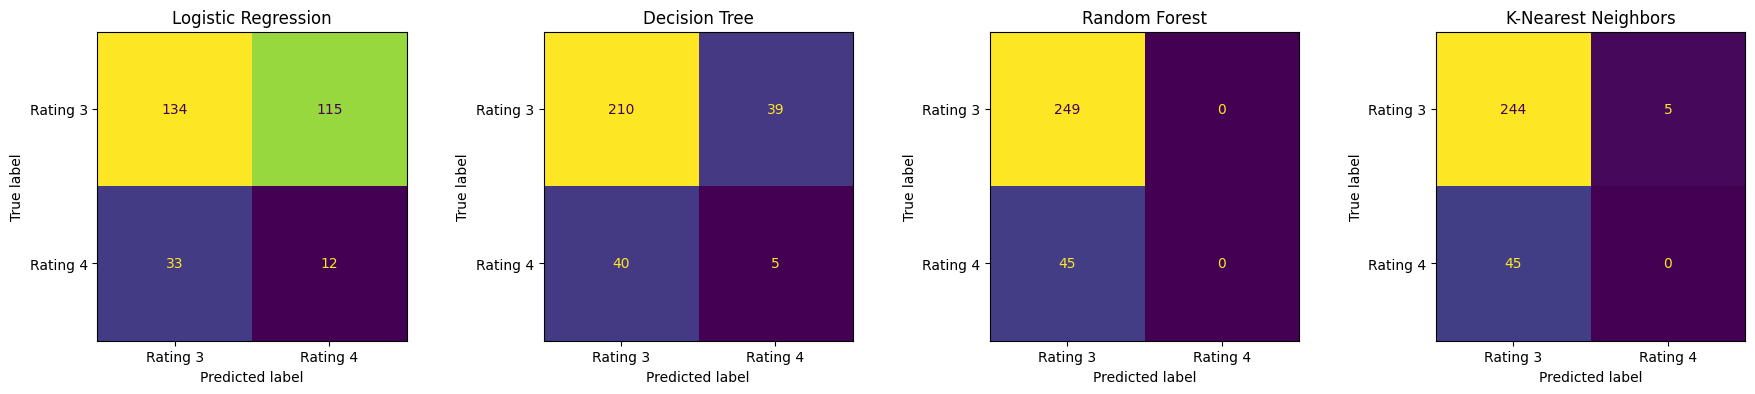

In [55]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, pipe) in zip(axes, pipelines_perf.items()):
    preds = pipe.predict(X_test_p)
    cm = confusion_matrix(y_test_p, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rating 3', 'Rating 4'])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

ROC curves

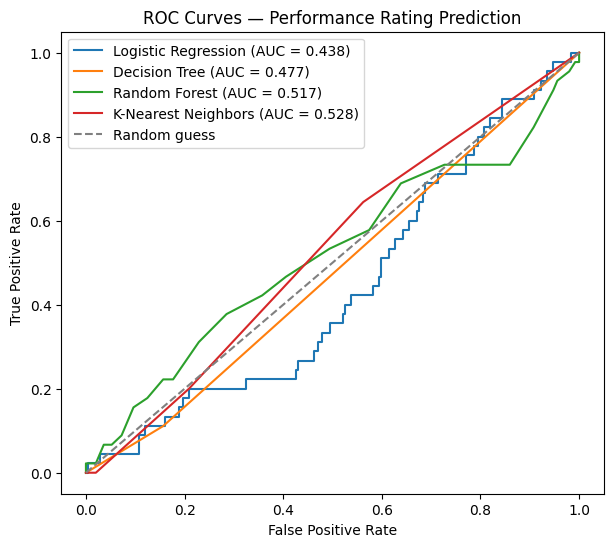

In [52]:
plt.figure(figsize=(7, 6))
for name, pipe in pipelines_perf.items():
    probs = pipe.predict_proba(X_test_p)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_p, probs)
    auc = roc_auc_score(y_test_p, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Performance Rating Prediction')
plt.legend()
plt.show()